# LightGBM + Optimized Feature Engineering
### AI Hack Thailand 2026 - 12-Month Default Flag Prediction

สมุดงานนี้พัฒนาต่อยอดจาก `LIGHTBGM.ipynb` โดยนำไอเดีย Feature Engineering มาผ่านการคัดกรองด้วย **5-Fold Stratified Cross-Validation**:
1. **คัดเฉพาะฟีเจอร์ที่เพิ่มคะแนนจริง (Signal):** เช่น `Existing_DTI`, `Total_Potential_DTI`, `Rent_to_Income_Ratio`, `Avg_Loan_Amount`
2. **ตัดฟีเจอร์ที่เป็น Noise และซ้ำซ้อนออก:** ปรับแก้การคำนวณหน่วยเงินให้ถูกต้องตามจริงใน dataset (ไม่คูณสเกลเกินจริง)
3. **กำหนด Categorical Dtypes:** เพื่อให้ LightGBM ดึงประสิทธิภาพของอัลกอริทึม **Optimal Categorical Splitting** มาใช้เต็มที่

In [50]:
%pip install pandas numpy scikit-learn seaborn matplotlib lightgbm

Note: you may need to restart the kernel to use updated packages.


In [51]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings('ignore')

In [52]:
train_path = "train_dataset.csv" if os.path.exists("train_dataset.csv") else r"C:\Users\ice55\Downloads\Aihack Thailand 2026\train_dataset.csv"
test_path = "test_without_gt.csv" if os.path.exists("test_without_gt.csv") else r"C:\Users\ice55\Downloads\Aihack Thailand 2026\test_without_gt.csv"
submission_path = "submission_template_for_test.csv" if os.path.exists("submission_template_for_test.csv") else r"C:\Users\ice55\Downloads\Aihack Thailand 2026\submission_template_for_test.csv"

train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)
submission_data = pd.read_csv(submission_path)

print(f"Train Shape: {train_data.shape}")
print(f"Test Shape:  {test_data.shape}")
print(f"Default Flag Ratio: {train_data['12-Month Default Flag'].mean():.2%}")

Train Shape: (68546, 27)
Test Shape:  (137091, 26)
Default Flag Ratio: 9.68%


## 1. Feature Engineering Pipeline
สร้างฟังก์ชันเพื่อแปลงข้อมูลให้ทั้ง **Train** และ **Test** ใช้ตรรกะเดียวกัน ป้องกัน Data Leakage:
- **Existing_DTI**: อัตราส่วนยอดหนี้เดิมเทียบกับรายได้ต่อปี
- **Total_Potential_DTI**: ภาระหนี้รวมทั้งหมดหากได้รับอนุมัติวงเงินใหม่เทียบกับรายได้
- **Rent_to_Income_Ratio**: สัดส่วนภาระค่าเช่าต่อรายได้ต่อเดือน
- **Disposable_Monthly_Income**: ประมาณการรายได้สุทธิหลังหักค่าเช่า
- **Avg_Loan_Amount**: ยอดหนี้เฉลี่ยต่อสัญญาที่มีอยู่
- **Borrowing_to_Limit_Ratio**: สัดส่วนหนี้เดิมเทียบกับวงเงินที่มาขอใหม่
- **Residence_to_Age_Ratio**: สัดส่วนระยะเวลาอยู่อาศัยเทียบกับอายุ (ความมั่นคงของการตั้งถิ่นฐาน)
- **Total_Contact_Channels**: จำนวนช่องทางการติดต่อที่สามารถติดต่อได้

In [53]:
raw_feature_cols = [
    'Application Channel', 'Gender', 'Marital Status', 'Age (in months)',
    'Residence Period (in months)', 'Occupation Category', 'Industry Category',
    'Employment Type Category', 'Insurance Type', 'Company Size Category',
    'Business Entity Type', 'Declared Annual Income', 'Payday',
    'Declared Number of Borrowings', 'Declared Borrowing Amount',
    'Desired Credit Limit', 'Residence Type', 'Rent Burden',
    'Residence Ownership Status', 'Number of Dependents',
    'Number of Dependent Children', 'Home Phone Number Available',
    'Mobile Phone Number Available', 'Employer Phone Number Available',
    'Driver Licence Number Available'
]

cat_cols = [
    'Application Channel', 'Gender', 'Marital Status',
    'Occupation Category', 'Industry Category', 'Employment Type Category',
    'Insurance Type', 'Company Size Category', 'Business Entity Type',
    'Residence Type', 'Residence Ownership Status'
]

def engineer_features(df):
    data = df.copy()
    
    # ตัวหารที่อาจเป็น 0 ให้แทนด้วย NaN เพื่อป้องกัน Inf (LightGBM รองรับ NaN อัตโนมัติ)
    inc_annual_safe = data['Declared Annual Income'].replace(0, np.nan)
    inc_monthly_safe = (data['Declared Annual Income'] / 12).replace(0, np.nan)
    n_borrow_safe = data['Declared Number of Borrowings'].replace(0, np.nan)
    age_months_safe = data['Age (in months)'].replace(0, np.nan)
    desired_limit_safe = data['Desired Credit Limit'].replace(0, np.nan)
    
    borrow_amt = data['Declared Borrowing Amount']
    desired_limit = data['Desired Credit Limit']
    rent_burden = data['Rent Burden']

    # 1. ภาระหนี้ต่อรายได้ (Existing & Total DTI)
    data['Existing_DTI'] = borrow_amt / inc_annual_safe
    data['Total_Potential_DTI'] = (borrow_amt + desired_limit) / inc_annual_safe
    
    # 2. ภาระค่าเช่าและรายได้คงเหลือ
    data['Rent_to_Income_Ratio'] = rent_burden / inc_monthly_safe
    data['Disposable_Monthly_Income'] = (data['Declared Annual Income'] / 12) - rent_burden
    
    # 3. โครงสร้างและพฤติกรรมการกู้
    data['Avg_Loan_Amount'] = borrow_amt / n_borrow_safe
    data['Borrowing_to_Limit_Ratio'] = borrow_amt / desired_limit_safe
    
    # 4. ความมั่นคงและช่องทางติดต่อ
    data['Residence_to_Age_Ratio'] = data['Residence Period (in months)'] / age_months_safe
    data['Total_Contact_Channels'] = (
        data['Home Phone Number Available'] +
        data['Mobile Phone Number Available'] +
        data['Employer Phone Number Available'] +
        data['Driver Licence Number Available']
    )
    
    # แปลง Categorical ให้เป็น category dtype สำหรับ LightGBM
    for col in cat_cols:
        if col in data.columns:
            data[col] = data[col].astype('category')
            
    return data

train_fe = engineer_features(train_data)
test_fe = engineer_features(test_data)

new_features = [
    'Existing_DTI', 'Total_Potential_DTI', 'Rent_to_Income_Ratio',
    'Disposable_Monthly_Income', 'Avg_Loan_Amount', 'Borrowing_to_Limit_Ratio',
    'Residence_to_Age_Ratio', 'Total_Contact_Channels'
]
all_feature_cols = raw_feature_cols + new_features

print(f"จำนวนฟีเจอร์เดิม: {len(raw_feature_cols)}")
print(f"จำนวนฟีเจอร์ใหม่: {len(new_features)}")
print(f"รวมทั้งหมด: {len(all_feature_cols)} features")

จำนวนฟีเจอร์เดิม: 25
จำนวนฟีเจอร์ใหม่: 8
รวมทั้งหมด: 33 features


## 2. การประเมินผลด้วย 5-Fold Stratified Cross-Validation
เปรียบเทียบระหว่างโมเดลเดิม (25 Raw Features) กับ โมเดลที่เพิ่มฟีเจอร์และจัดการ Categorical (33 Features)

In [54]:
X_raw = train_data[raw_feature_cols]
X_fe = train_fe[all_feature_cols]
y = train_fe['12-Month Default Flag']

# พารามิเตอร์ที่ผ่านการปรับจูน (Tuned Parameters)
clf_model = LGBMClassifier(
    n_estimators=275,
    max_depth=14,
    num_leaves=20,
    class_weight='balanced',
    subsample=0.834,
    subsample_freq=1,
    learning_rate=0.019,
    random_state=42,
    verbose=-1
)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

print("กำลังคำนวณ 10-Fold CV...")
cv_scores_raw = cross_val_score(clf_model, X_raw, y, cv=cv, scoring='roc_auc')
cv_scores_fe = cross_val_score(clf_model, X_fe, y, cv=cv, scoring='roc_auc')

print("=" * 60)
print(f"Baseline (25 Raw Features)      CV ROC-AUC: {cv_scores_raw.mean():.5f} (+/- {cv_scores_raw.std():.5f})")
print(f"Optimized FE (33 Features)      CV ROC-AUC: {cv_scores_fe.mean():.5f} (+/- {cv_scores_fe.std():.5f})")
print(f"Improvement (คะแนนที่เพิ่มขึ้น):            {cv_scores_fe.mean() - cv_scores_raw.mean():+.5f}")
print("=" * 60)

กำลังคำนวณ 10-Fold CV...
Baseline (25 Raw Features)      CV ROC-AUC: 0.64787 (+/- 0.01172)
Optimized FE (33 Features)      CV ROC-AUC: 0.65005 (+/- 0.01194)
Improvement (คะแนนที่เพิ่มขึ้น):            +0.00218


In [55]:
import numpy as np

# รายชื่อ 4 คอลัมน์ที่ต้องการแปลงเป็น Log
skewed_cols = [
    'Declared Annual Income',      # รายได้ต่อปี
    'Rent Burden',                # ค่าเช่า
    'Declared Borrowing Amount',  # ยอดหนี้เดิม
    'Desired Credit Limit'        # วงเงินที่ขอ
]

# แปลงทั้ง Train และ Test ด้วย np.log1p (ป้องกันค่าติดลบด้วย np.maximum)
for col in skewed_cols:
    train_data[col] = np.log1p(np.maximum(train_data[col], 0))
    test_data[col] = np.log1p(np.maximum(test_data[col], 0))

print("แปลง 4 ฟีเจอร์เป็น log1p เรียบร้อยแล้ว!")

แปลง 4 ฟีเจอร์เป็น log1p เรียบร้อยแล้ว!


## 3. Train-Test Split & Detailed Model Evaluation
แบ่ง Train/Test ชุดตรวจวัด (80/20 Stratified Split) เพื่อดู Confusion Matrix, F1-Score, Precision และ Recall

,Metric,Score
0,Accuracy,0.631364
1,Precision,0.147665
2,Recall,0.588546
3,F1-score,0.236094
4,ROC-AUC,0.656777


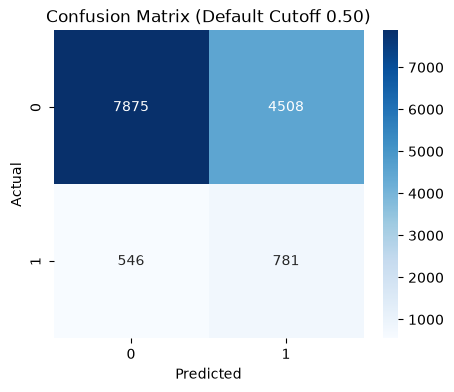

              precision    recall  f1-score   support

           0       0.94      0.64      0.76     12383
           1       0.15      0.59      0.24      1327

    accuracy                           0.63     13710
   macro avg       0.54      0.61      0.50     13710
weighted avg       0.86      0.63      0.71     13710



{'Accuracy': 0.6313639679066375,
 'Precision': 0.14766496502174323,
 'Recall': 0.5885455915599096,
 'F1-score': 0.23609431680773882,
 'ROC-AUC': 0.6567771249216707}

In [56]:
x_train_split, x_test_split, y_train_split, y_test_split = train_test_split(
    X_fe, y, test_size=0.2, random_state=42, stratify=y
)

clf_model.fit(x_train_split, y_train_split)
y_pred = clf_model.predict(x_test_split)
y_prob = clf_model.predict_proba(x_test_split)[:, 1]

def evaluate_model(y_true, y_pred, y_prob=None):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
    }
    if y_prob is not None:
        metrics["ROC-AUC"] = roc_auc_score(y_true, y_prob)

    display(pd.DataFrame(metrics.items(), columns=["Metric", "Score"]))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title("Confusion Matrix (Default Cutoff 0.50)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    print(classification_report(y_true, y_pred, zero_division=0))
    return metrics

evaluate_model(y_test_split, y_pred, y_prob)

## 4. วิเคราะห์ Feature Importances
สังเกตว่าฟีเจอร์ใหม่ที่สร้างขึ้น (เช่น `Total_Potential_DTI`, `Existing_DTI`, `Borrowing_to_Limit_Ratio`) ติดอันดับสำคัญที่สุดในการตัดสินใจของโมเดล

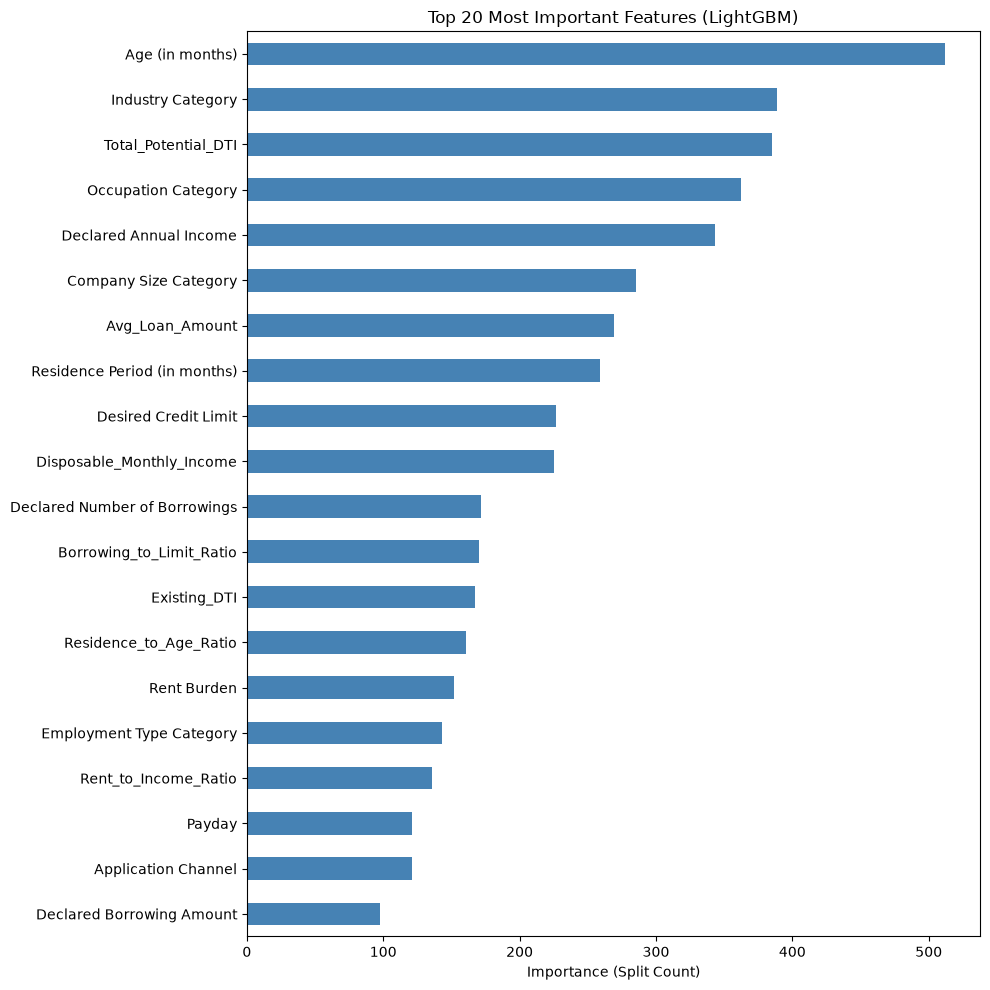

In [57]:
importances = pd.Series(clf_model.feature_importances_, index=all_feature_cols)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(10, 10))
importances.tail(20).plot(kind='barh', color='steelblue')
plt.title("Top 20 Most Important Features (LightGBM)")
plt.xlabel("Importance (Split Count)")
plt.tight_layout()
plt.show()

## 5. Threshold Optimization
ในโจทย์ Class Imbalance การปรับ Threshold จาก 0.50 สามารถช่วยบาลานซ์ Precision และ Recall ตามเป้าหมายทางธุรกิจได้

In [58]:
fpr, tpr, thresholds = roc_curve(y_test_split, y_prob)
youden_idx = np.argmax(tpr - fpr)
best_thresh = thresholds[youden_idx]

print(f"Optimal Youden's Threshold: {best_thresh:.4f}")

# ลองเปรียบเทียบผลที่ Threshold ต่างๆ
for th in [0.40, 0.50, round(best_thresh, 2), 0.60]:
    p = (y_prob >= th).astype(int)
    f1 = f1_score(y_test_split, p, zero_division=0)
    rec = recall_score(y_test_split, p, zero_division=0)
    prec = precision_score(y_test_split, p, zero_division=0)
    print(f"Threshold: {th:.2f} | F1: {f1:.4f} | Recall: {rec:.4f} | Precision: {prec:.4f}")

Optimal Youden's Threshold: 0.4772
Threshold: 0.40 | F1: 0.2119 | Recall: 0.8531 | Precision: 0.1210
Threshold: 0.50 | F1: 0.2361 | Recall: 0.5885 | Precision: 0.1477
Threshold: 0.48 | F1: 0.2335 | Recall: 0.6541 | Precision: 0.1421
Threshold: 0.60 | F1: 0.2180 | Recall: 0.2607 | Precision: 0.1873


## 6. Test Set Prediction & Submission Export
เทรนโมเดลด้วยชุดข้อมูลทั้งหมด (Full Train Data) เพื่อให้โมเดลเรียนรู้จากข้อมูลมากที่สุดก่อนทำนาย Test Set

In [63]:
# เทรนโมเดลกับข้อมูล Train ทั้งหมด
final_model = LGBMClassifier(
    n_estimators=275,
    max_depth=14,
    num_leaves=20,
    class_weight='balanced',
    subsample=0.834,
    subsample_freq=1,
    learning_rate=0.019,
    random_state=42,
    verbose=-1
)
final_model.fit(X_fe, y)

# ทำนายความน่าจะเป็นของ Test Set
X_test_final = test_fe[all_feature_cols]
test_prob = final_model.predict_proba(X_test_final)[:, 1]

# กำหนด Threshold (เช่น 0.50 หรือตามการปรับจูน)
chosen_threshold = 0.5
test_pred = (test_prob >= chosen_threshold).astype(int)

submission = pd.DataFrame({
    'ID': test_data['ID'].values,
    '12-Month Default Flag': test_pred
})

print("Shape:", submission.shape)
print("Distribution:")
print(submission['12-Month Default Flag'].value_counts(normalize=True))

# บันทึกเป็นไฟล์ใหม่ (แยกจากไฟล์เดิม ไม่ทับไฟล์อื่นๆ)
submission_output_path = 'submission_lightGBM_fe_optimized_v4.csv'
#submission.to_csv(submission_output_path, index=False)
print(f"พร้อมส่งออกเป็น: {submission_output_path} (หากต้องการบันทึกให้ uncomment บรรทัดด้านบน)")

Shape: (137091, 2)
Distribution:
12-Month Default Flag
0    0.605729
1    0.394271
Name: proportion, dtype: float64
พร้อมส่งออกเป็น: submission_lightGBM_fe_optimized_v4.csv (หากต้องการบันทึกให้ uncomment บรรทัดด้านบน)


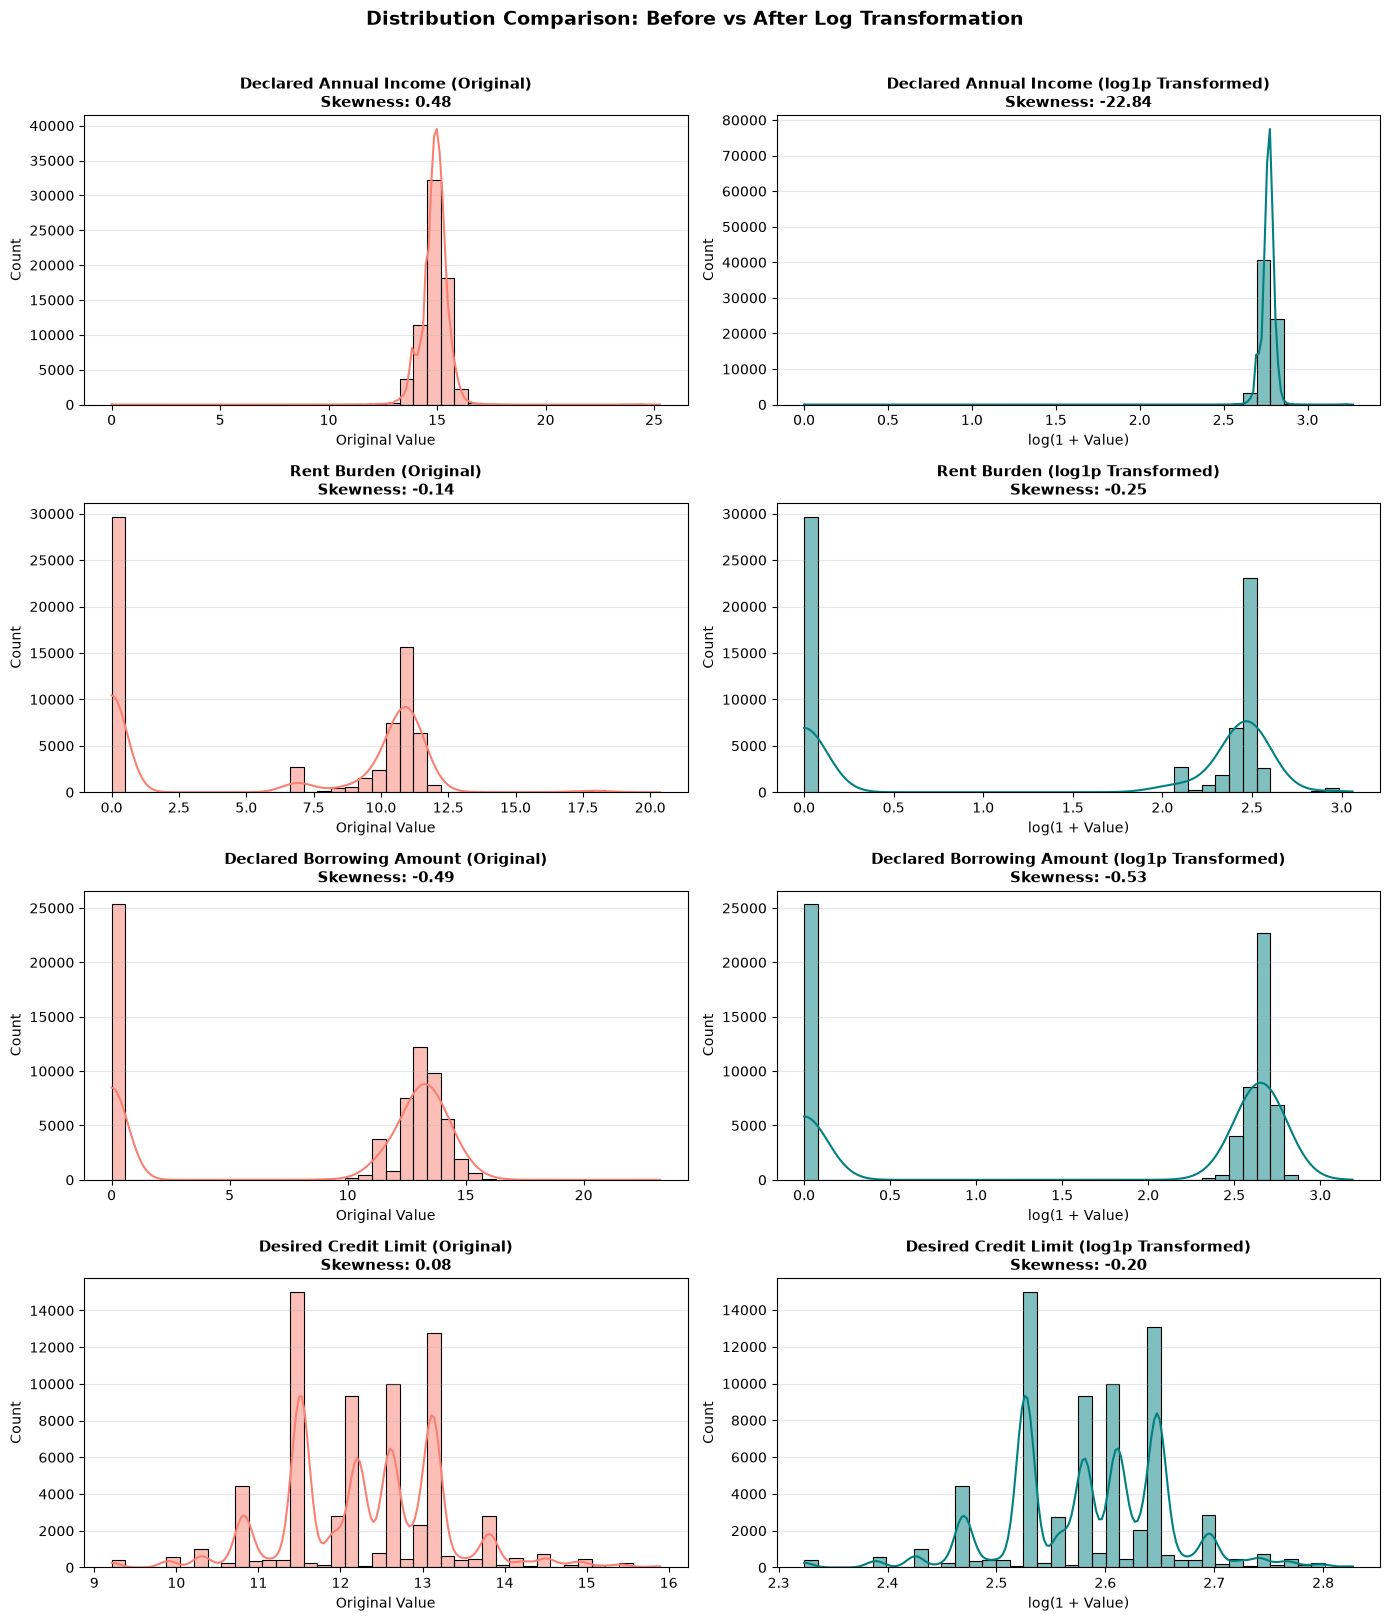

In [61]:
if 'Factors_train_data' in locals():
    df_plot = Factors_train_data
elif 'train_data' in locals():
    df_plot = train_data
elif 'train_fe' in locals():
    df_plot = train_fe
else:
    # หากยังไม่ได้โหลดข้อมูล ให้โหลดจากไฟล์โดยตรง
    df_plot = pd.read_csv("train_dataset.csv")
# รายชื่อคอลัมน์ที่มีค่าเบ้สูงมาก
skewed_cols = [
    'Declared Annual Income',      # รายได้ต่อปี
    'Rent Burden',                # ค่าเช่า
    'Declared Borrowing Amount',  # ยอดหนี้เดิม
    'Desired Credit Limit'        # วงเงินที่ขอ
]
# สร้าง Subplots เปรียบเทียบซ้าย-ขวา
fig, axes = plt.subplots(len(skewed_cols), 2, figsize=(14, 4 * len(skewed_cols)))
for idx, col in enumerate(skewed_cols):
    # 1. ข้อมูลเดิม
    orig_data = df_plot[col].dropna()
    skew_orig = orig_data.skew()
    
    # 2. ทำ Log Transform ด้วย np.log1p
    log_data = np.log1p(np.maximum(orig_data, 0))
    skew_log = log_data.skew()
    
    # --- กราฟซ้าย: ก่อนทำ Log (Original Distribution) ---
    sns.histplot(orig_data, kde=True, bins=40, ax=axes[idx, 0], color='salmon')
    axes[idx, 0].set_title(f"{col} (Original)\nSkewness: {skew_orig:.2f}", fontsize=11, fontweight='bold')
    axes[idx, 0].set_xlabel("Original Value")
    axes[idx, 0].set_ylabel("Count")
    axes[idx, 0].grid(axis='y', alpha=0.3)
    
    # --- กราฟขวา: หลังทำ Log (log1p Distribution) ---
    sns.histplot(log_data, kde=True, bins=40, ax=axes[idx, 1], color='teal')
    axes[idx, 1].set_title(f"{col} (log1p Transformed)\nSkewness: {skew_log:.2f}", fontsize=11, fontweight='bold')
    axes[idx, 1].set_xlabel("log(1 + Value)")
    axes[idx, 1].set_ylabel("Count")
    axes[idx, 1].grid(axis='y', alpha=0.3)
plt.suptitle("Distribution Comparison: Before vs After Log Transformation", fontsize=14, y=1.01, fontweight='bold')
plt.tight_layout()
plt.show()